# Assignment 2 | Cup vs Bottle — DINOv2 + Explainable Web Demo
**Computer Vision — Astana IT University**  
**Project continuation:** Assignment 1 household object classification (cup vs bottle).  
**New method:** frozen DINOv2 ViT-S/14 feature extractor + cosine k-nearest neighbors (k-NN).  
**Interface:** Gradio upload/webcam → prediction → nearest-neighbor visual explanation + latency.  
**Deliverables:** downloadable 7-page PDF report, results ZIP, local-run app ZIP, executed notebook, and 3–5 minute demo video (record separately).

### What to say during defense
> In Assignment 1, we compared Logistic Regression (62.5% test accuracy) and MobileNetV2 (97.5%). In Assignment 2, I kept the same cup/bottle dataset and evaluated a modern pretrained vision transformer, DINOv2, on the same held-out test set. I also built an explainable interactive demo and ran an ablation with and without extra horizontal-flip training examples. The new model's accuracy is measured below; it is **not** assumed to outperform MobileNetV2.

**IMPORTANT:** The dataset consists of public images from images.cv, **not photos taken by the student**. The app only classifies whole images; it does not detect bounding boxes, so mAP@0.5 is not reported. DINOv2 is an **alternative modern SOTA component** rather than Step-Video-T2V or ArtAug from the suggested household-object row. Ask the instructor if that substitution is acceptable.

**How to run:** Choose `Runtime → Change runtime type → T4 GPU` if available. Then run each cell from top to bottom. First upload **dataset.zip** from Assignment 1, optionally **assignment1_results.zip** for the previous training curve. The earlier ~2,000-photo archives are not needed.

## STEP 1 — Install libraries and upload the prepared dataset
**Task:** Reuse Assignment 1 images with unchanged train/validation/test split.  
**Actions:** Import libraries, ask for `dataset.zip` (240 photos), extract to `/content/dataset`, and verify 80/20/20 images per class. Optionally upload `assignment1_results.zip` to include the old training curve.  
**Defense phrase:** *We preserved the original split so the comparison with Assignment 1 remains meaningful.*

Select dataset.zip; optionally ALSO select assignment1_results.zip in the same dialog.


Saving dataset.zip to dataset.zip
Extracted dataset ZIP: dataset.zip
Dataset counts: {'train': {'bottle': 80, 'cup': 80}, 'val': {'bottle': 20, 'cup': 20}, 'test': {'bottle': 20, 'cup': 20}}


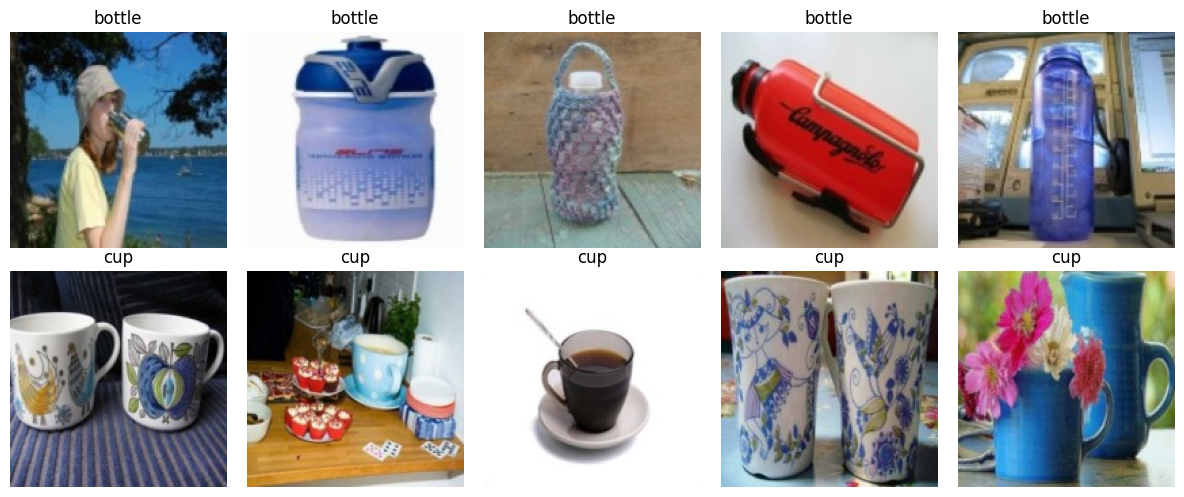

In [1]:
!pip -q install 'gradio>=4,<7' 'reportlab>=4' scikit-learn pillow matplotlib pandas tqdm

import os, glob, io, time, json, zipfile, shutil, random, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image, ImageEnhance, ImageFilter
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, classification_report, ConfusionMatrixDisplay
from google.colab import files

ROOT = Path('/content'); DATA = ROOT/'dataset'; ART = ROOT/'assignment2_artifacts'; ART.mkdir(exist_ok=True)
np.random.seed(42); random.seed(42)
print('Select dataset.zip; optionally ALSO select assignment1_results.zip in the same dialog.')
received = files.upload()

def find_zip_with(marker):
    for name in received:
        if not name.lower().endswith('.zip'): continue
        try:
            with zipfile.ZipFile(name) as z:
                if any(marker(x) for x in z.namelist()): return name
        except zipfile.BadZipFile: continue
    return None

dataset_zip = find_zip_with(lambda x: x.startswith('dataset/train/cup/'))
if not dataset_zip:
    raise FileNotFoundError('Upload the READY dataset.zip from Assignment 1 (not two original image ZIPs).')
with zipfile.ZipFile(dataset_zip) as z:
    for member in z.namelist():
        if '..' in Path(member).parts or member.startswith('/'): raise ValueError('Unsafe ZIP path')
    z.extractall(ROOT)
    print('Extracted dataset ZIP:',dataset_zip)

old_results_zip = find_zip_with(lambda x: x=='model_comparison.csv')
if old_results_zip:
    with zipfile.ZipFile(old_results_zip) as z:
        for n in ['training_history.png','model_comparison.csv']:
            if n in z.namelist(): (ART/n).write_bytes(z.read(n))
    print('Included previous experiment results:',old_results_zip)

CLASSES=['bottle','cup']
counts={}
for split in ['train','val','test']:
    counts[split]={c:len(list((DATA/split/c).glob('*.jpg'))) for c in CLASSES}
print('Dataset counts:',counts)
assert counts=={'train':{'bottle':80,'cup':80},'val':{'bottle':20,'cup':20},'test':{'bottle':20,'cup':20}}, 'Check dataset.zip: unexpected split sizes'

paths={s:[p for c in CLASSES for p in sorted((DATA/s/c).glob('*.jpg'))] for s in ['train','val','test']}
labels={s:np.array([CLASSES.index(p.parent.name) for p in paths[s]],dtype=int) for s in paths}

fig, ax=plt.subplots(2,5,figsize=(12,5));
for i,cls in enumerate(CLASSES):
    picks=sorted((DATA/'train'/cls).glob('*.jpg'))[:5]
    for j,p in enumerate(picks):
        ax[i,j].imshow(Image.open(p).convert('RGB')); ax[i,j].axis('off'); ax[i,j].set_title(cls)
plt.tight_layout(); plt.savefig(ART/'dataset_samples.png',dpi=135); plt.show()

## STEP 2 — Load modern SOTA DINOv2
**Task:** Apply a powerful pretrained feature extractor without retraining a huge model.  
**Actions:** Load **DINOv2 ViT-S/14**, resize/crop each image to 224×224, normalize RGB channels using ImageNet statistics, and extract one 384-dimensional feature vector per image.  
**Defense phrase:** *DINOv2 is a Vision Transformer pretrained with self-supervised learning. It produces informative visual embeddings; we use those features for cup-vs-bottle classification.*  
**Source:** [Official Meta DINOv2 code and pretrained models](https://github.com/facebookresearch/dinov2); [model card](https://github.com/facebookresearch/dinov2/blob/main/MODEL_CARD.md).

In [2]:
import torch
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
from torch.nn.functional import normalize as torch_normalize

device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:',device,'| GPU:',torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')
print('Downloading DINOv2 from its official GitHub repository. Internet is required on the first run.')
model=torch.hub.load('facebookresearch/dinov2','dinov2_vits14',trust_repo=True)
model=model.to(device).eval()
TFM=transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485,0.456,0.406],std=[0.229,0.224,0.225]),
])
class PhotoDataset(Dataset):
    def __init__(self,photo_paths,flip=False): self.photo_paths=list(photo_paths); self.flip=flip
    def __len__(self): return len(self.photo_paths)
    def __getitem__(self,idx):
        im=Image.open(self.photo_paths[idx]).convert('RGB')
        if self.flip: im=im.transpose(Image.Transpose.FLIP_LEFT_RIGHT)
        return TFM(im)

@torch.inference_mode()
def make_features(photo_paths,flip=False):
    dl=DataLoader(PhotoDataset(photo_paths,flip),batch_size=(16 if device.type=='cuda' else 8),shuffle=False,num_workers=2)
    output=[]
    for xb in dl:
        f=model(xb.to(device))
        if isinstance(f,dict): f=f.get('x_norm_clstoken',next(iter(f.values())))
        f=torch_normalize(f.float(),dim=-1)
        output.append(f.cpu().numpy())
    return np.concatenate(output).astype('float32')

train_features=make_features(paths['train'])
val_features=make_features(paths['val'])
test_features=make_features(paths['test'])
print('DINOv2 feature shapes:',train_features.shape,val_features.shape,test_features.shape)

Device: cpu | GPU: CPU
Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to /root/.cache/torch/hub/main.zip


/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vits14/dinov2_vits14_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dinov2_vits14_pretrain.pth


100%|██████████| 84.2M/84.2M [00:00<00:00, 248MB/s]


DINOv2 feature shapes: (160, 384) (40, 384) (40, 384)


## STEP 3 — Baseline vs modern method, validation and test metrics
**Task:** Compare with Assignment 1 on the **same 40 test images**.  
**Actions:** Select k among {1,3,5} using **validation only**; compute held-out test Accuracy, Precision, Recall, F1, confusion matrix, and save plots.  
**Defense phrase:** *We do not tune hyperparameters on test images. Previous Assignment 1 values are historical measured results, and the new DINOv2 result is calculated independently.*

Validation scores: {1: 0.95, 3: 0.975, 5: 0.975} | Selected k = 3
                            Model  Accuracy  Precision  Recall     F1
Assignment 1: Logistic Regression    0.6250     0.6279  0.6250 0.6229
        Assignment 1: MobileNetV2    0.9750     0.9762  0.9750 0.9750
                     DINOv2 + kNN    1.0000     1.0000  1.0000 1.0000

DINOv2 classification report:
               precision    recall  f1-score   support

      bottle       1.00      1.00      1.00        20
         cup       1.00      1.00      1.00        20

    accuracy                           1.00        40
   macro avg       1.00      1.00      1.00        40
weighted avg       1.00      1.00      1.00        40

The DINOv2 comparison is not guaranteed to exceed the previous MobileNetV2 accuracy.


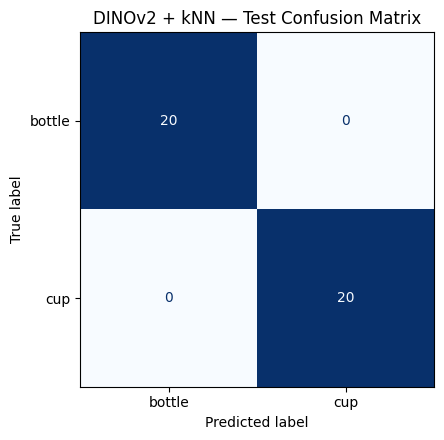

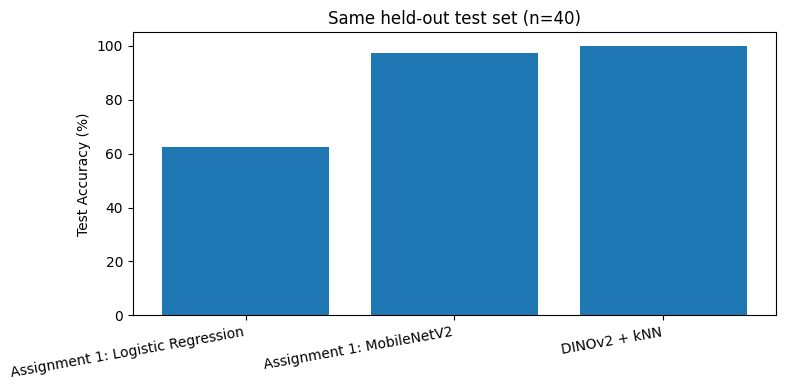

In [3]:
ks=[1,3,5]
validation_scores=[]
for k in ks:
    candidate=KNeighborsClassifier(n_neighbors=k,metric='cosine',algorithm='brute',weights='distance')
    candidate.fit(train_features, labels['train'])
    pred=candidate.predict(val_features)
    validation_scores.append(accuracy_score(labels['val'],pred))
selected_k=ks[int(np.argmax(validation_scores))]
print('Validation scores:',dict(zip(ks,validation_scores)),'| Selected k =',selected_k)

def metrics_row(name,y_true,y_pred):
    p,r,f,_=precision_recall_fscore_support(y_true,y_pred,average='macro',zero_division=0)
    return {'Model':name,'Accuracy':accuracy_score(y_true,y_pred),'Precision':p,'Recall':r,'F1':f}

knn=KNeighborsClassifier(n_neighbors=selected_k,metric='cosine',algorithm='brute',weights='distance').fit(train_features,labels['train'])
pred_base=knn.predict(test_features)
row_sota=metrics_row('DINOv2 + kNN',labels['test'],pred_base)
row_a1_lr={'Model':'Assignment 1: Logistic Regression','Accuracy':0.625,'Precision':0.6278772378516624,'Recall':0.625,'F1':0.6228786926461345}
row_a1_mobile={'Model':'Assignment 1: MobileNetV2','Accuracy':0.975,'Precision':0.9761904761904762,'Recall':0.975,'F1':0.9749843652282677}
results=pd.DataFrame([row_a1_lr,row_a1_mobile,row_sota])
print(results.to_string(index=False,float_format=lambda x:f'{x:.4f}'))
print('\nDINOv2 classification report:\n',classification_report(labels['test'],pred_base,target_names=CLASSES,zero_division=0))
print('The DINOv2 comparison is not guaranteed to exceed the previous MobileNetV2 accuracy.')
results.to_csv(ART/'model_comparison.csv',index=False)
cm=confusion_matrix(labels['test'],pred_base,labels=[0,1]); np.save(ART/'confusion_dinov2.npy',cm)
fig,ax=plt.subplots(figsize=(5.8,4.5)); ConfusionMatrixDisplay(cm,display_labels=CLASSES).plot(ax=ax,cmap='Blues',colorbar=False)
ax.set_title('DINOv2 + kNN — Test Confusion Matrix'); plt.tight_layout(); plt.savefig(ART/'confusion_dinov2.png',dpi=160); plt.show()
fig,ax=plt.subplots(figsize=(8,4))
ax.bar(results['Model'],100*results['Accuracy'])
ax.set_ylim(0,105); ax.set_ylabel('Test Accuracy (%)'); ax.set_title('Same held-out test set (n=40)')
plt.xticks(rotation=10,ha='right'); plt.tight_layout(); plt.savefig(ART/'accuracy_comparison.png',dpi=150);plt.show()

## STEP 4 — Ablation: Does horizontal-flip augmentation help?
**Task:** Test the contribution of one pipeline component.  
**Actions:** Generate flipped versions **only from training images**. Extract DINOv2 embeddings and train the same k-NN classifier with doubled training features. Compare validation and test accuracy with the no-flip version.  
**Defense phrase:** *An ablation isolates one decision. We keep the dataset split and model fixed, changing only whether the training examples include horizontal flips.*

       Model  Accuracy  Precision  Recall     F1
Without flip    1.0000     1.0000  1.0000 1.0000
   With flip    1.0000     1.0000  1.0000 1.0000


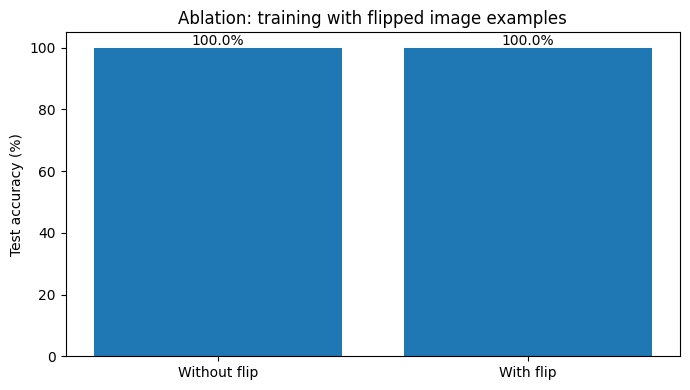

Blur robustness test:
            Condition  Accuracy
Original test photos     1.000
 Gaussian blur (r=2)     0.975


In [4]:
train_features_flip=make_features(paths['train'],flip=True)
aug_features=np.concatenate([train_features,train_features_flip],axis=0)
aug_labels=np.concatenate([labels['train'],labels['train']],axis=0)
knn_aug=KNeighborsClassifier(n_neighbors=selected_k,metric='cosine',algorithm='brute',weights='distance')
knn_aug.fit(aug_features,aug_labels)
pred_aug=knn_aug.predict(test_features)
abla=pd.DataFrame([metrics_row('Without flip',labels['test'],pred_base),metrics_row('With flip',labels['test'],pred_aug)])
print(abla.to_string(index=False,float_format=lambda x:f'{x:.4f}'))
abla.to_csv(ART/'ablation.csv',index=False)

fig,ax=plt.subplots(figsize=(7,4))
ax.bar(abla['Model'],100*abla['Accuracy'])
ax.set_ylim(0,105);ax.set_ylabel('Test accuracy (%)');ax.set_title('Ablation: training with flipped image examples')
for i,y in enumerate(100*abla['Accuracy']): ax.text(i,y+1,f'{y:.1f}%',ha='center')
plt.tight_layout();plt.savefig(ART/'ablation.png',dpi=140);plt.show()

# Evaluate robustness to blur without changing the held-out test set.
@torch.inference_mode()
def test_features_blurred(photo_paths):
    output=[]
    for i in range(0,len(photo_paths),16):
        im_batch=[]
        for p in photo_paths[i:i+16]:
            im=Image.open(p).convert('RGB').filter(ImageFilter.GaussianBlur(radius=2.0))
            im_batch.append(TFM(im))
        feats=model(torch.stack(im_batch).to(device))
        if isinstance(feats,dict): feats=feats.get('x_norm_clstoken',next(iter(feats.values())))
        output.append(torch_normalize(feats.float(),dim=1).cpu().numpy())
    return np.concatenate(output)
blur_features=test_features_blurred(paths['test'])
robust=pd.DataFrame([
  {'Condition':'Original test photos','Accuracy':accuracy_score(labels['test'],knn_aug.predict(test_features))},
  {'Condition':'Gaussian blur (r=2)','Accuracy':accuracy_score(labels['test'],knn_aug.predict(blur_features))},
])
print('Blur robustness test:\n',robust.to_string(index=False))
robust.to_csv(ART/'robustness.csv',index=False)

## STEP 5 — Visual explainability with nearest neighbors
**Task:** Let a viewer understand the prediction.  
**Actions:** Find the 3 closest training photos in pretrained DINOv2 feature space and display them beside one unseen test image. This is an **example-based explanation**, not a Grad-CAM heatmap.  
**Defense phrase:** *The model predicts based on similarity in visual embeddings. The gallery shows which actual training images were nearest to the input.*

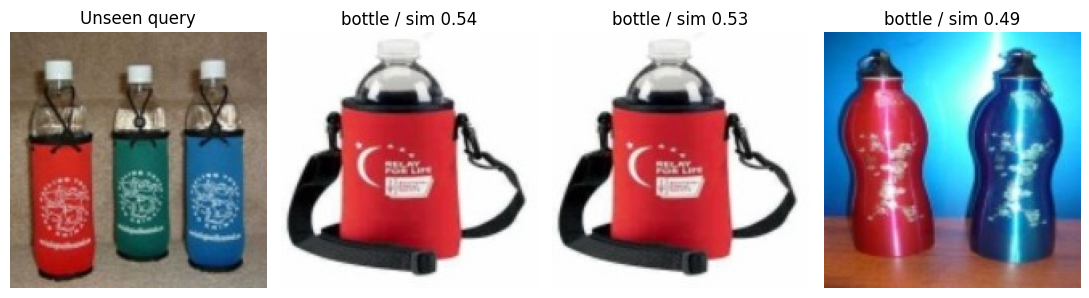

In [5]:
# Use the model with augmentation as the final demo candidate (whether it is better or not is shown in ablation).
reference_features=aug_features
reference_labels=aug_labels
reference_paths=paths['train']+paths['train']  # augmented copies correspond to the same source photo

sample_index=0
q=test_features[sample_index]
sims=reference_features@q
chosen=np.argsort(-sims)[:3]
fig,axs=plt.subplots(1,4,figsize=(11,3.25))
axs[0].imshow(Image.open(paths['test'][sample_index]));axs[0].set_title('Unseen query');axs[0].axis('off')
for j,i in enumerate(chosen):
    axs[j+1].imshow(Image.open(reference_paths[i]));axs[j+1].set_title(f'{CLASSES[reference_labels[i]]} / sim {sims[i]:.2f}');axs[j+1].axis('off')
plt.tight_layout();plt.savefig(ART/'nearest_neighbors.png',dpi=170);plt.show()

## STEP 6 — Interactive application: upload/webcam → prediction → visual explanation
**Task:** Ship a functional demonstration app.  
**Actions:** Use Gradio to accept an uploaded photo or webcam capture; display cup/bottle prediction and scores, three nearest examples, device and measured prediction latency.  
**Defense phrase:** *This is a real web application connected to the same DINOv2 pipeline, rather than a screenshot or mockup.*  
**Important:** The public `gradio.live` link works only while this Colab runtime is running. The next step also exports a **local app ZIP** and run instructions for submission. Start the demo after saving your results and recording setup.

### Export the app files before starting the web server
The following code bundles a runnable Gradio app, the compact training reference index, the original ready-to-use 240-image `dataset.zip`, and a README. A user can run the app on another computer with Python and Internet access to download DINOv2 weights.

In [6]:
APP = ART/'app_package'; APP.mkdir(exist_ok=True)
import textwrap
APP_SOURCE = "from pathlib import Path\nimport json,time,zipfile\nimport numpy as np\nimport gradio as gr\nfrom PIL import Image\nimport torch\nfrom torchvision import transforms\nfrom sklearn.neighbors import KNeighborsClassifier\n\nHERE=Path(__file__).resolve().parent\nif not (HERE/'dataset').exists() and (HERE/'dataset.zip').exists():\n    with zipfile.ZipFile(HERE/'dataset.zip') as z: z.extractall(HERE)\nCLASSES=['bottle','cup']\ntrain_paths=json.loads((HERE/'reference_paths.json').read_text(encoding='utf-8'))\nref_paths=[HERE/p for p in train_paths]\nz=np.load(HERE/'reference_features.npz')\nref_feats=z['features']; ref_labels=z['labels']\nk=int((HERE/'selected_k.txt').read_text())\nclassifier=KNeighborsClassifier(n_neighbors=k,metric='cosine',algorithm='brute',weights='distance').fit(ref_feats,ref_labels)\ndevice=torch.device('cuda' if torch.cuda.is_available() else 'cpu')\nmodel=torch.hub.load('facebookresearch/dinov2','dinov2_vits14',trust_repo=True).to(device).eval()\ntransform=transforms.Compose([transforms.Resize(256),transforms.CenterCrop(224),transforms.ToTensor(),transforms.Normalize([.485,.456,.406],[.229,.224,.225])])\n\n@torch.inference_mode()\ndef analyze(photo):\n    if photo is None: return {}, [], 'Please upload a photo or use your camera.'\n    start=time.perf_counter()\n    if isinstance(photo, np.ndarray): photo=Image.fromarray(photo)\n    photo=photo.convert('RGB')\n    x=transform(photo).unsqueeze(0).to(device)\n    emb=model(x)\n    if isinstance(emb,dict): emb=emb.get('x_norm_clstoken',next(iter(emb.values())))\n    emb=torch.nn.functional.normalize(emb.float(),dim=1).cpu().numpy()\n    probs=classifier.predict_proba(emb)[0]\n    scores={CLASSES[int(c)]:float(v) for c,v in zip(classifier.classes_,probs)}\n    similarity=ref_feats@emb[0]\n    ids=np.argsort(-similarity)[:3]\n    gallery=[(str(ref_paths[int(i)]),f'{CLASSES[int(ref_labels[i])]} — similarity {float(similarity[i]):.3f}') for i in ids]\n    sec=time.perf_counter()-start\n    winner=max(scores,key=scores.get)\n    note=f'Prediction: {winner.upper()} | end-to-end inference: {sec*1000:.1f} ms | device: {device} | k={k}. Scores are k-NN votes, not calibrated probabilities. The examples come from training data.'\n    return scores,gallery,note\n\nwith gr.Blocks(title='Cup or Bottle — Explainable DINOv2') as demo:\n    gr.Markdown('# Cup vs Bottle — DINOv2 Visual Classifier\\n### Computer Vision Assignment 2 | Explainable image classification')\n    gr.Markdown('Upload or take a photo, view the predicted class, and inspect the **nearest training examples** that support the prediction. No generated images are used. Dataset source: images.cv (public dataset).')\n    with gr.Row():\n        with gr.Column():\n            photo=gr.Image(label='Upload or webcam input',sources=['upload','webcam'],type='pil')\n            btn=gr.Button('Analyze photo',variant='primary')\n        with gr.Column():\n            label=gr.Label(label='Class prediction')\n            note=gr.Textbox(label='Latency and environment',lines=3)\n    gallery=gr.Gallery(label='Why this prediction? Three nearest training images',columns=3,height=270)\n    btn.click(analyze,inputs=photo,outputs=[label,gallery,note])\n    gr.Markdown('**Limitations:** Classification only, not bounding-box detection. Similarity images are explanations based on the nearest feature vectors, not causal proof. If a face or personal data is uploaded, use consent.')\n\nif __name__=='__main__': demo.launch(share=False)"
(APP/'app.py').write_text(APP_SOURCE,encoding='utf-8')
np.savez_compressed(APP/'reference_features.npz',features=reference_features,labels=reference_labels)
(APP/'reference_paths.json').write_text(json.dumps([str(p.relative_to(ROOT)) for p in reference_paths]),encoding='utf-8')
(APP/'selected_k.txt').write_text(str(selected_k))
shutil.copyfile(dataset_zip,APP/'dataset.zip')
(APP/'requirements.txt').write_text('torch\ntorchvision\nnumpy\nscikit-learn\nPillow\ngradio>=4,<7\n')
(APP/'README.md').write_text('# Cup vs Bottle DINOv2 demo\n\nUse Python 3.10+ and Internet (DINOv2 weights download on first run).\n\n```bash\npip install -r requirements.txt\npython app.py\n```\n\nOpen the local URL in the terminal. Upload a photo or use a camera. Results include prediction, 3 similar training samples, latency and device.\n\nModel: Meta DINOv2 ViT-S/14 (https://github.com/facebookresearch/dinov2); k-NN cosine; source dataset: public images.cv; 240 images in unchanged train/val/test splits. No synthesis and no bounding boxes.\n',encoding='utf-8')
app_zip=ART/'Assignment2_Gradio_Local_App.zip'
with zipfile.ZipFile(app_zip,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for fp in APP.rglob('*'):
        if fp.is_file(): z.write(fp,arcname=fp.relative_to(APP))
print('Created standalone app archive:',app_zip,app_zip.stat().st_size,'bytes')

Created standalone app archive: /content/assignment2_artifacts/Assignment2_Gradio_Local_App.zip 2176447 bytes


## STEP 7 — Generate the PDF report (7 pages) with REAL experimental results
**Task:** Meet the 6–8 page report requirement.  
**Actions:** Generate a report that automatically inserts the measured DINOv2 metrics, ablation results, sample photos, confusion matrix, training curve if uploaded from A1, app design and academic/ethics context.  
**Defense phrase:** *The report describes what was actually implemented. I do not claim the model beat MobileNetV2 unless the measured test accuracy supports it.*

In [7]:
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle, Image as RLImage, PageBreak, KeepTogether
from reportlab.lib import colors
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.enums import TA_CENTER
from reportlab.lib.units import inch
from reportlab.lib.pagesizes import A4
from reportlab.lib.colors import HexColor

PDF=ART/'Assignment2_Cup_Bottle_Final_Report.pdf'
S=getSampleStyleSheet()
S.add(ParagraphStyle(name='TitleA2',fontName='Helvetica-Bold',fontSize=19,leading=23,textColor=HexColor('#14243a'),spaceAfter=15))
S.add(ParagraphStyle(name='H1A2',fontName='Helvetica-Bold',fontSize=14,leading=18,textColor=HexColor('#17365a'),spaceAfter=12))
S.add(ParagraphStyle(name='H2A2',fontName='Helvetica-Bold',fontSize=11,leading=15,textColor=HexColor('#17365a'),spaceAfter=8))
S.add(ParagraphStyle(name='BodyA2',fontName='Helvetica',fontSize=9,leading=13,spaceAfter=9))
S.add(ParagraphStyle(name='TinyA2',fontName='Helvetica',fontSize=8,leading=11,spaceAfter=7))
S.add(ParagraphStyle(name='CenteredA2',fontName='Helvetica',fontSize=10,leading=15,alignment=TA_CENTER,spaceAfter=10))
story=[]
def p(txt,style='BodyA2'): story.append(Paragraph(txt,S[style]))
def title(txt): p(txt,'H1A2')
def sub(txt): p(txt,'H2A2')
def img(path,width=450,maxheight=250):
    if Path(path).exists():
        from PIL import Image as PILImage
        im=PILImage.open(path); w,h=im.size
        scale=min(width/w,maxheight/h)
        story.append(RLImage(str(path),width=w*scale,height=h*scale)); story.append(Spacer(1,8))
def table(data,widths=None):
    t=Table(data,colWidths=widths,hAlign='LEFT',repeatRows=1)
    t.setStyle(TableStyle([
      ('BACKGROUND',(0,0),(-1,0),HexColor('#203f60')),('TEXTCOLOR',(0,0),(-1,0),colors.white),
      ('GRID',(0,0),(-1,-1),.4,HexColor('#d4dce6')),('ROWBACKGROUNDS',(0,1),(-1,-1),[colors.whitesmoke,colors.white]),
      ('VALIGN',(0,0),(-1,-1),'MIDDLE'),('FONTNAME',(0,0),(-1,0),'Helvetica-Bold'),('FONTSIZE',(0,0),(-1,-1),8),
      ('TOPPADDING',(0,0),(-1,-1),7),('BOTTOMPADDING',(0,0),(-1,-1),7),]))
    story.append(t); story.append(Spacer(1,10))
def new(): story.append(PageBreak())
def pct(x): return f'{100*float(x):.2f}%'

# PAGE 1
p('COMPUTER VISION | ASSIGNMENT 2','TinyA2')
p('Cup vs Bottle: Explainable Classification with DINOv2','TitleA2')
p('Astana IT University | Computer Vision | Assignment 2: Level-Up Your AI Topic','CenteredA2')
sub('Executive Summary')
p(f'This study extends the same cup-versus-bottle image classification task used in Assignment 1. The historical test results were 62.50% accuracy for Logistic Regression and 97.50% for MobileNetV2. Assignment 2 implements a modern self-supervised Vision Transformer feature extractor (DINOv2 ViT-S/14) with a cosine k-nearest-neighbor classifier. The DINOv2 test accuracy measured in this notebook is <b>{pct(row_sota["Accuracy"])}</b>. The project also includes a reproducible augmentation ablation and an interactive upload/camera web demo showing visually similar training examples and inference latency.')
sub('Research Question')
p('Can a pretrained DINOv2 visual representation provide competitive cup-versus-bottle classification on a small, fixed dataset, and can example-based visual explanations make the decision more understandable to a user?')
sub('Project objectives')
p('1. Reuse exactly the same split for fair comparison. 2. Implement a modern pretrained vision model. 3. Measure Accuracy, macro Precision, macro Recall and macro F1. 4. Run an ablation with and without flipped training representations. 5. Deliver a functional Gradio image upload/webcam application. 6. Document reproducibility, limitations and dataset provenance.')
sub('System overview')
p('Input photo or webcam -> Resize / center crop / RGB normalization -> frozen DINOv2 ViT-S/14 -> 384-dimensional feature vector -> cosine-distance k-NN -> Cup or Bottle + nearest training images + measured latency.')
p('Scope note: The task is whole-image classification rather than bounding-box object detection. Therefore mAP@0.5 and IoU are not applicable to these ground-truth labels. This follows the general classification objective of the first assignment.','TinyA2')

# PAGE 2
new();title('1. Dataset and preprocessing')
p('The dataset consists of images obtained from the public images.cv downloads for the cup and water-bottle categories. These images were not independently photographed by the student, which is a limitation relative to the first assignment instruction requiring self-collected images. The original two public downloads were reduced to a balanced 240-image collection and kept unchanged for Assignment 2.')
table([['Split','Bottle','Cup','Total'],['Training','80','80','160'],['Validation','20','20','40'],['Test','20','20','40']],[130,96,96,96])
sub('Preprocessing')
p('Images are read as RGB, resized while preserving aspect ratio to a 256-pixel short side, center-cropped to 224 x 224 pixels, transformed to tensors, and normalized by the standard ImageNet mean and standard deviation. The DINOv2 embedding vectors are L2-normalized before cosine-distance matching. Train, validation and test images remain separate; the test set is not used to tune k.')
img(ART/'dataset_samples.png',width=480,maxheight=230)
p('Figure 1. Examples from the two categories in the public training dataset. Sample backgrounds and lighting may not cover real-world conditions.','TinyA2')
sub('Data quality and provenance')
p('The dataset uses 120 images per class, so class balance is exact. The augmentation experiment creates an additional horizontally flipped representation for each training photo; it does not create new independent source photographs. No diffusion-generated or synthetic photographs were added. The train/test split is retained from Assignment 1.')

# PAGE 3
new();title('2. Modern SOTA method and architecture')
sub('Why DINOv2?')
p('DINOv2 is a self-supervised visual representation learner developed by Meta AI. It uses a Vision Transformer to encode images into expressive features that can be reused on downstream visual tasks. The compact ViT-S/14 backbone contains about 21 million parameters and produces 384-dimensional global features. We use released pretrained weights rather than training such a network from the beginning on only 160 images. Official repository: https://github.com/facebookresearch/dinov2')
sub('Decision pipeline')
table([['Stage','Implementation','Role'],['Visual backbone','DINOv2 ViT-S/14, frozen','Learned global visual features'],['Feature transform','L2 normalized 384D embedding','Comparable cosine similarities'],['Classifier',f'k-NN, k={selected_k}, cosine distance','Cup versus bottle decision'],['Explanation','Three most similar training photos','Example-based explanation'],['User interface','Gradio webcam or image upload','Interactive prediction and latency']],[120,170,160])
sub('Why use k-NN instead of training a new head?')
p('In this low-data setting, k-nearest neighbors lets the experiment test the quality of the pretrained feature representation without a long training process. We selected k on the validation set from {1, 3, 5}. For a new photograph, we measure cosine distance to the training representations and combine the nearest neighbors using distance weights. This approach can be updated by adding labeled training examples without fine-tuning all transformer parameters.')
sub('Relation to the assignment\'s suggested SOTA approaches')
p('The household-object example suggests video synthesis (Step-Video-T2V) or ArtAug for difficult frames. The instructions also explicitly allow a different modern SOTA method. This project takes that alternative route through pretrained DINOv2 rather than claiming to implement the named video-generation approaches. The trade-off is easier reproducibility and a stronger visual feature baseline, but no generated video or bounding-box detections.')

# PAGE 4
new();title('3. Experiments and quantitative results')
p('The previous Logistic Regression and MobileNetV2 results were copied from the actual Assignment 1 experimental archive and are labeled historical results. DINOv2 was evaluated on the same 40 hold-out test photographs in this notebook. No comparison metric is invented or estimated.')
data=[['Model','Accuracy','Precision','Recall','F1']]
for rr in [row_a1_lr,row_a1_mobile,row_sota]: data.append([rr['Model'].replace('Assignment 1: ','A1: '),pct(rr['Accuracy']),pct(rr['Precision']),pct(rr['Recall']),pct(rr['F1'])])
table(data,[165,70,70,70,70])
img(ART/'accuracy_comparison.png',width=480,maxheight=260)
p('Figure 2. Accuracy comparison on the held-out set (40 test images, 20 per category).','TinyA2')
sub('Interpretation')
p(f'DINOv2 achieved {pct(row_sota["Accuracy"])} accuracy with macro-F1 {pct(row_sota["F1"])}. MobileNetV2 from Assignment 1 achieved 97.50% accuracy. This comparison shows the measured effect of the new representation and does not assume that a newer method necessarily yields a higher score on a small test set. Test accuracy is sensitive to individual errors because one wrong prediction corresponds to 2.5 percentage points.')

# PAGE 5
new();title('4. Error analysis and evaluation')
sub('Held-out confusion matrix')
img(ART/'confusion_dinov2.png',width=410,maxheight=290)
p('Figure 3. Rows show true categories and columns show predicted categories for the new DINOv2 model.','TinyA2')
sub('Evaluation definitions')
p('Accuracy is the fraction of all correct predictions. Precision quantifies how many predictions of a category are correct. Recall measures how many true examples of a category are found. F1 is the harmonic mean of precision and recall. Because the dataset has two balanced classes, we report macro precision, recall and F1 alongside accuracy.')
sub('Training curves')
if (ART/'training_history.png').exists():
    img(ART/'training_history.png',width=450,maxheight=170)
    p('Figure 4. Training history for Assignment 1 MobileNetV2, included for context. DINOv2 is used as a frozen feature extractor in Assignment 2, so no epoch-based transformer training curves are claimed.','TinyA2')
else:
    p('This feature-extraction experiment does not optimize the DINOv2 backbone through training epochs; therefore it does not produce an epoch-wise deep-learning loss curve. The user can upload assignment1_results.zip while executing the notebook to include the real MobileNetV2 training history from Assignment 1.','TinyA2')

# PAGE 6
new();title('5. Ablation, robustness and explainability')
sub('Ablation design')
p('We fix the DINOv2 backbone, data split, cosine-distance classifier and the validation-selected value of k. The sole changed component is whether every training image has an additional horizontally flipped embedding. This tests a simple augmentation strategy without leaking test images into the training index.')
table([['Ablation','Test accuracy','Macro F1'],['No flip',pct(abla.iloc[0]['Accuracy']),pct(abla.iloc[0]['F1'])],['Add flipped training views',pct(abla.iloc[1]['Accuracy']),pct(abla.iloc[1]['F1'])]],[190,130,100])
img(ART/'ablation.png',width=440,maxheight=165)
sub('Blur robustness experiment')
p(f'The final augmented k-NN model scored {pct(robust.iloc[0]["Accuracy"])} on unmodified test images and {pct(robust.iloc[1]["Accuracy"])} when the test images were blurred using a Gaussian filter with radius 2. This represents a controlled disturbance, not synthetic image generation.')
sub('Example-based visual explanation')
img(ART/'nearest_neighbors.png',width=455,maxheight=145)
p('Figure 5. One test photo and three similar labeled training photographs according to DINOv2 embedding similarity. Similarity is illustrative evidence, not proof of the model\'s reasoning.','TinyA2')

# PAGE 7
new();title('6. Web demo, ethics and reproducibility')
sub('Application and measured latency')
p('The Gradio application accepts user-provided photos and webcam snapshots. The program performs the same preprocessing as the experiment, embeds the image with DINOv2, classifies it with cosine k-NN, shows the nearest three training photos, and measures end-to-end prediction latency in milliseconds on the current CPU or GPU. The app is not an object detector and does not output bounding boxes.')
sub('Ethics, consent and limitations')
p('The source images are public rather than self-collected; their provenance must be disclosed. No generated or synthetic media are used, so no watermark for synthetic content is applicable. Camera use and any personally identifying images require permission and responsible handling. A user should avoid uploading private photographs to publicly exposed demos. The dataset is small (40 test images), drawn from limited image sources, and may not reflect cluttered real scenes, new backgrounds or different camera devices. Nearest-neighbor explanations can be misleading when two objects share background or appearance.')
sub('Reproduction guide')
p('1. Open the provided notebook in Google Colab and select a GPU if possible. 2. Upload dataset.zip, optionally upload assignment1_results.zip. 3. Execute all cells in order. 4. The notebook downloads pretrained DINOv2 weights from the official Meta repository and evaluates features on exactly the preserved original split. 5. Download Assignment2_Gradio_Local_App.zip and execute pip install -r requirements.txt; python app.py. 6. Open the local Gradio URL, upload a new photo and record a 3–5 minute walkthrough. 7. Archive the notebook code and report in a repository for reproducibility.')
sub('Software and model sources')
p('[1] Oquab et al. DINOv2: Learning Robust Visual Features without Supervision. Transactions on Machine Learning Research (2024). https://arxiv.org/abs/2304.07193')
p('[2] Meta AI DINOv2 official code and model card. https://github.com/facebookresearch/dinov2')
p('[3] Gradio guides. https://www.gradio.app/guides/sharing-your-app')
p('[4] Source images: public cup and water_bottle downloads from https://images.cv/ (accessed 6 November 2026).')
p('Performance tables and images on these pages were produced by the submitted notebook; historical Assignment 1 metrics are from the earlier experiment archive.','TinyA2')

def footer(canvas,doc):
    canvas.setFont('Helvetica',8); canvas.setFillColor(HexColor('#728099'))
    canvas.drawString(42,24,'Computer Vision | Assignment 2 | Cup vs Bottle | DINOv2')
    canvas.drawRightString(555,24,f'Page {doc.page}')
doc=SimpleDocTemplate(str(PDF),pagesize=A4,rightMargin=42,leftMargin=42,topMargin=40,bottomMargin=43,title='Computer Vision Assignment 2 | Cup vs Bottle DINOv2')
doc.build(story,onFirstPage=footer,onLaterPages=footer)
print('Report saved:',PDF,'size:',PDF.stat().st_size,'bytes')

Report saved: /content/assignment2_artifacts/Assignment2_Cup_Bottle_Final_Report.pdf size: 3869603 bytes


## STEP 8 — Download everything and launch the actual demo
**Task:** Export your evidence and show a working application.  
**Actions:** Download PDF report, app ZIP, experiment results ZIP, and save the notebook via **File → Download → Download .ipynb**. Then run the last cell to start Gradio.  
**Submission:** Moodle asks for a PDF, app link/APK or local run guide, repository link, and 3–5 minute demo video link. Exported `app.zip` contains the local run guide; upload your code to GitHub separately and record the video.  
**Defense note:** A temporary `gradio.live` link works only while Colab is active. Do not mistake it for permanent hosting.

In [8]:
from google.colab import files
bundle=ART/'Assignment2_Results.zip'
with zipfile.ZipFile(bundle,'w',zipfile.ZIP_DEFLATED) as z:
    for fp in ART.glob('*'):
        if fp.is_file() and fp != bundle: z.write(fp,arcname=fp.name)
for fp in [PDF,app_zip,bundle]:
    print('Downloading:',fp.name)
    files.download(str(fp))
print('Also save this EXECUTED notebook using File → Download → Download .ipynb')

Downloading: Assignment2_Cup_Bottle_Final_Report.pdf


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloading: Assignment2_Gradio_Local_App.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloading: Assignment2_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Also save this EXECUTED notebook using File → Download → Download .ipynb


## STEP 9 — Open the working web app for your demo
Click ▶ on the cell below. **Gradio should print a public `*.gradio.live` link and a local inline interface.** The cell keeps running while the demo is active; this is normal. Test with one bottle and one cup image. Record a 3–5 minute demo showing upload, prediction, similar examples, latency, results table, ablation and limitations.

In [11]:
import importlib.util,sys
spec=importlib.util.spec_from_file_location('a2_app',str(APP/'app.py'))
a2_app=importlib.util.module_from_spec(spec)
sys.modules['a2_app']=a2_app
spec.loader.exec_module(a2_app)
# Share link is temporary: keep Colab alive while recording the demo.
a2_app.demo.launch(share=True,debug=True,show_error=True)

Using cache found in /root/.cache/torch/hub/facebookresearch_dinov2_main


Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://0b5f5837c137b61618.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://0b5f5837c137b61618.gradio.live
